## RaNNDy for protein folding 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

from matplotlib.colors import ListedColormap
import time
import jax.random as random
import sys
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")
import optimal_ranndy
import importlib
importlib.reload(optimal_ranndy)
from optimal_ranndy import RaNNDy
plt.ion()

import mdtraj as md
import os
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          # or 'sans-serif', 'monospace', etc.
plt.rcParams['font.serif'] = ['Computer Modern Serif']  

#from contact_map import ContactFrequency, ContactDifference, ContactMap, ContactTrajectory, RollingContactFrequency, ResidueContactConcurrence, plot_concurrence

## Protein-folding data from DE Shaw Research. The data can be acquired from [https://www.deshawresearch.com/]

In [2]:
# Load data  #TODO: Please change the paths here

molecule = 'nug2'  # or 'chignolin'

data_dir = "/home/s2421480/Documents/MD_datasets/"

if molecule == 'nug2':
    molecule_traj_dir = "ProteinG/NuG2-0-protein/"     
else:
    molecule_traj_dir = "Chignolin/CLN025-0-protein/"

# Load .dcd files trajectories
traj_names = []
    
molecule_dir = data_dir + molecule_traj_dir

for filename in sorted(os.listdir(molecule_dir)):
    file_path = os.path.join(molecule_dir, filename)
    traj_names.append(file_path)


In [3]:
# load trajectory with the molecule topology

if molecule == 'nug2':
    path_to_molecule_topology = '/home/s2421480/Documents/MD_datasets/ProteinG/NuG2pdb.pdb'     
else:
    path_to_molecule_topology = '/home/s2421480/Documents/MD_datasets/Chignolin/chignolin_pdb.pdb'
    
traj = md.load(traj_names[::2], top=path_to_molecule_topology) ## for chignolin select whole trajectory

# # to take singel copy of chain
# if molecule == 'nug2':
#     top = traj.topology

#     atoms_first56 = [atom.index for atom in top.atoms if atom.residue.index < 56]
#     traj = traj.atom_slice(atoms_first56)


dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and

In [4]:
traj

<mdtraj.Trajectory with 929251 frames, 846 atoms, 112 residues, and unitcells at 0x791edc116990>

In [4]:
# Create the data matrices

traj_X = traj[:-50:50]
traj_Y = traj[50::50]

dis_X = md.compute_contacts(traj_X, contacts='all', scheme='closest-heavy')
dis_Y = md.compute_contacts(traj_Y, contacts='all', scheme='closest-heavy')

data_X = (dis_X[0]).T
data_Y = (dis_Y[0]).T

## RaNNDy

In [8]:

n_eigfuncs = 10  # Number of eigenfunctions to compute
kwargs = {} # only needed for Hamiltonian operator
key = random.PRNGKey(seed=0)
w_init = [0.001, 0.001]

domain_eigf = data_X  # Domain for eigenfunctions

# randomzed neural network for Koopman operator
ranndy = RaNNDy(
    X=data_X,
    operator='koopman',
    hidden_sizes=[256, 512, 256],
    activation="tanh",
    init_weights_dist='normal', 
    init_weights_std=1.0,
    init_bias_dist='normal',
    init_bias_std=1.0,
    random_state=0
)

In [9]:
## Operator eigendecomposition initial

start_time = time.time()  # Start time for RNN eigendecomposition
# eigvals and eigenvectors approximation
eigvals_i, eigvecs_i = ranndy.operator_eig_decomp(
    w=w_init,
    X=data_X,
    Y=data_Y,
    Z=None,
    params=None,
    n=n_eigfuncs,
    epsilon=1e-5,
    kwargs=kwargs)

end_time = time.time()  # End time for RNN eigendecomposition
time_i = end_time - start_time
print(f"RNN eigendecomposition time: {time_i:.2f} seconds")

eigfuncs_i = ranndy.eigenfunctions(
    w=w_init,
    eigvecs=eigvecs_i,
    domain=domain_eigf,
    )

RNN eigendecomposition time: 1.78 seconds


## Optimize activation

In [12]:
## Optimize activation

w_gd, loss_w, w_vals, opt_params = ranndy.optimize_activation(w_init=w_init, X=data_X, Y=data_Y, n=n_eigfuncs, epochs=10, lr=0.01, lr_schedule='constant', epsilon=1e-5, get_epoch=2)

Epoch 0, Loss: -1.0000
Time for one step of RaNNDy optimization: 2.6781 seconds
Epoch 2, Loss: -19.5923
Time for one step of RaNNDy optimization: 0.4453 seconds
Epoch 4, Loss: -20.8367
Time for one step of RaNNDy optimization: 0.5098 seconds
Epoch 6, Loss: -20.8111
Time for one step of RaNNDy optimization: 0.4343 seconds
Epoch 8, Loss: -19.5212
Time for one step of RaNNDy optimization: 0.4265 seconds


w_gd:  [Array(-0.01932206, dtype=float32), Array(-0.04650665, dtype=float32)]


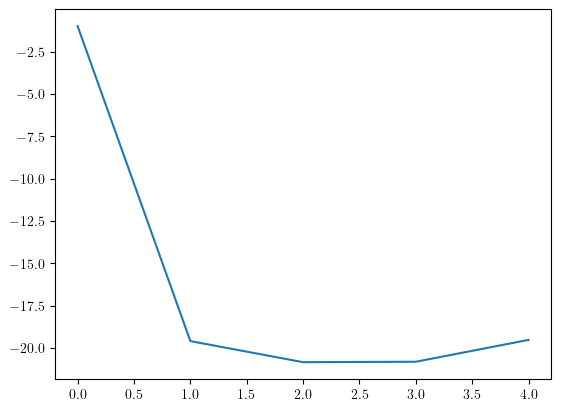

In [13]:
print('w_gd: ', w_gd)
plt.plot(loss_w)

In [14]:
## Operator eigendecomposition final

start_time = time.time()  # Start time for RNN eigendecomposition
# eigvals and eigenvectors approximation
eigvals_f, eigvecs_f = ranndy.operator_eig_decomp(
    w=w_gd,
    X=data_X,
    Y=data_Y,
    Z=None,
    params=None,
    n=n_eigfuncs,
    epsilon=1e-5,
    kwargs=kwargs)

end_time = time.time()  # End time for RNN eigendecomposition
time_f = end_time - start_time
print(f"RNN eigendecomposition time: {time_f:.2f} seconds")

eigfuncs_f = ranndy.eigenfunctions(
    w=w_gd,
    eigvecs=eigvecs_f,
    domain=domain_eigf,
    )

RNN eigendecomposition time: 1.01 seconds


/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


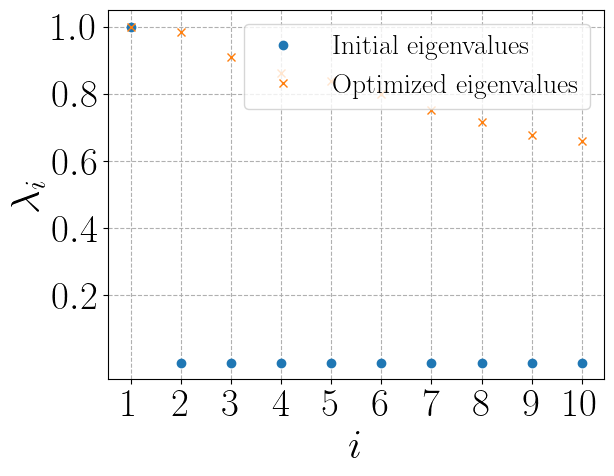

In [15]:
xx = np.arange(1, 11, step=1)
plt.figure()
plt.plot(xx, eigvals_i, 'o', label='Initial eigenvalues')
plt.plot(xx, eigvals_f, 'x', label='Optimized eigenvalues')
plt.grid(which="minor", linestyle=":")
plt.grid(which="major", linestyle="--")
plt.xlabel(r"$i$", fontsize=30)
plt.ylabel(r"$\lambda_i$", fontsize=30)
plt.legend(fontsize=20, loc='upper right')
plt.xticks(np.arange(1, 11, 1), fontsize=28)
plt.yticks(np.arange(0.2, 1.1, 0.2), fontsize=28)
#plt.savefig('../figures/nug2_eigvals.pdf', bbox_inches='tight', dpi=300)
plt.show()

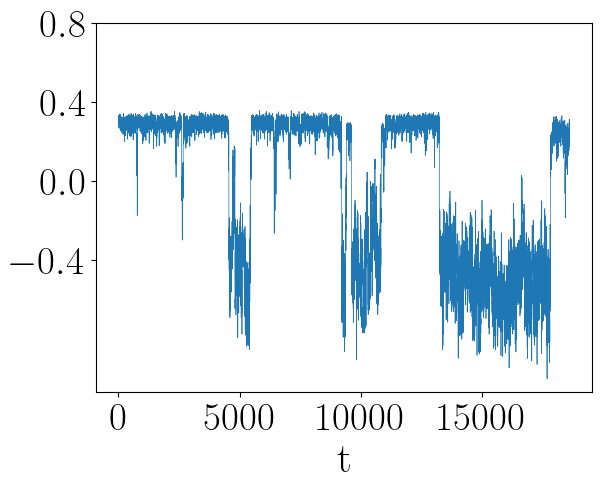

In [26]:
# eigenfunctions plot

k = 1
r_i = eigfuncs_i[k, :]
r_f = eigfuncs_f[k, :]
eigf2_i = np.real(r_i/np.amax(np.abs(r_i))).reshape(data_X.shape[1], 1)
eigf2_f = np.real(r_f/np.amax(np.abs(r_f))).reshape(data_X.shape[1], 1)

plt.figure()
#plt.plot(eigf2_i, linewidth=0.5, label = 'Initial RaNNDy')
plt.plot(-eigf2_f, linewidth=0.5, label = 'Optimized RaNNDy')
#plt.legend(fontsize=17, loc='upper left')
plt.xlabel('t', fontsize=30)
#plt.ylabel('Eigenfunction', fontsize=37)
plt.xticks(np.arange(0, 20000, 5000), fontsize=28)
plt.yticks(np.arange(-0.4, 1.1, 0.4), fontsize=28)
#plt.savefig('../figures/nug2_eigfuncs.pdf', bbox_inches='tight', dpi=300)
plt.show()

## Extracting the states

In [18]:
## Divide the states based on a cutoff

#cutoff_i = 0.0
cutoff_f = 0.0

# states_1_i = list(i for i, x in enumerate(eigf2_i) if x > cutoff_i)
# states_2_i = list(i for i, x in enumerate(eigf2_i) if x < cutoff_i)
states_1_f = list(i for i, x in enumerate(eigf2_f) if x < cutoff_f)
states_2_f = list(i for i, x in enumerate(eigf2_f) if x > cutoff_f)

In [19]:
# Getting the frmaes from trajectory for each state for RNN

# state_1_frames_i = traj_X[states_1_i]
# state_2_frames_i = traj_X[states_2_i]


# Getting the frmaes from trajectory for each state for VAMPNets

state_1_frames_f = traj_X[states_1_f]
state_2_frames_f = traj_X[states_2_f]

In [20]:
# print('Number of frames in state 1 using RNN: ', len(states_1_i))
# print('Number of frames in state 2 using RNN: ', len(states_2_i))
print('Number of frames in state 1 using VAMPNets: ', len(states_1_f))
print('Number of frames in state 2 using VAMPNets: ', len(states_2_f))

Number of frames in state 1 using VAMPNets:  11417
Number of frames in state 2 using VAMPNets:  7168


## Calculate the accracy to report as number of misclassified frames/total frames. Optimize RNN more before reporting final accuracies.

In [21]:
# # saving the frames for final approximation

state_1_frames_f.save_pdb('/home/s2421480/Documents/MD_datasets/ProteinG/state_1_final_ranndy')
state_2_frames_f.save_pdb('/home/s2421480/Documents/MD_datasets/ProteinG/state_2_final_ranndy')

# # # saving the frames for rnn

# state_1_frames_i.save_pdb('/home/s2421480/Documents/MD_datasets/ProteinG/state_1_i')
# state_2_frames_i.save_pdb('/home/s2421480/Documents/MD_datasets/ProteinG/state_2_i')

## Contact map of the trajectories

In [22]:
from contact_map import ContactFrequency

In [29]:
folded_contact_freq = ContactFrequency(state_1_frames_f)
#unfolded_contact_freq = ContactFrequency(state_2_frames_f)
#part_folded_contact_freq = ContactFrequency(part_folded_frames, cutoff=0.5)

/tmp/ipykernel_7833/3149993939.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  seismic = cm.get_cmap('seismic', 256)


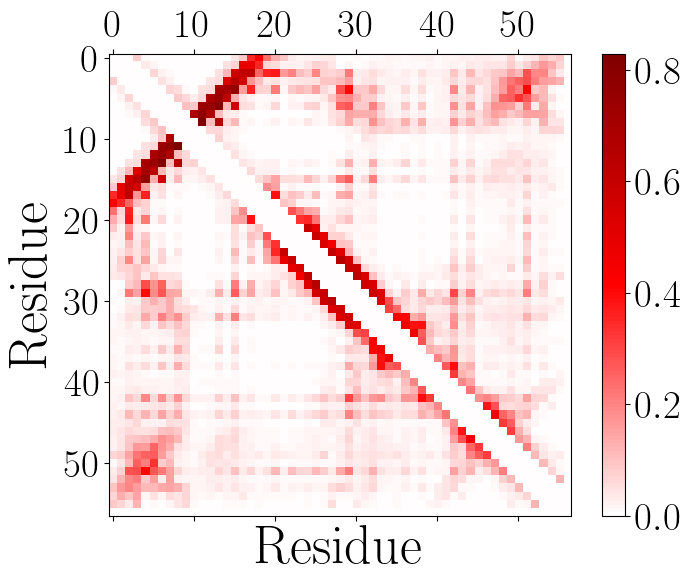

In [ ]:
contact_df = unfolded_contact_freq.residue_contacts.df

# Slice first 61 residues
subset_df = contact_df.loc[0:56, 0:56]

# Replace NaNs with 0
subset_df_clean = subset_df.fillna(0)

# Prepare the plot
fig, ax = plt.subplots(figsize=(8, 6))

seismic = cm.get_cmap('seismic', 256)
white_to_red = ListedColormap(seismic(np.linspace(0.5, 1, 256)))

# Plot using matshow
cax = ax.matshow(subset_df_clean.values, cmap=white_to_red)

# Customize axes
plt.xlabel("Residue", fontsize=39)
plt.ylabel("Residue", fontsize=39)
plt.xticks(range(0, 57, 10), fontsize=28)
plt.yticks(range(0, 57, 10), fontsize=28)

# Add colorbar
cbar = fig.colorbar(cax)
cbar.ax.tick_params(labelsize=28)
#plt.savefig('../figures/nug2_unfolded_contact.pdf', bbox_inches='tight', dpi=300)
plt.show()

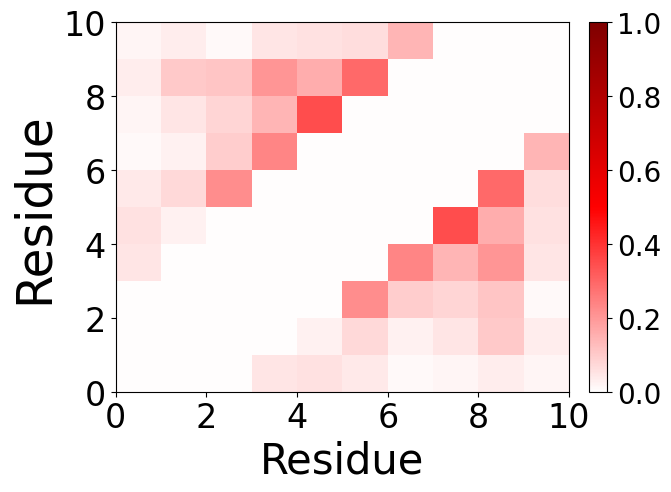

In [55]:
#%%time

fig, ax = folded_contact_freq.residue_contacts.plot()
#fig, ax = part_folded_contact_freq.residue_contacts.plot()
#fig, ax = unfolded_contact_freq.residue_contacts.plot()

plt.xlabel("Residue", fontsize=30)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
#plt.colorbar(fontsize=24)
fig.axes[1].yaxis.set_tick_params(labelsize=20)
_ = plt.ylabel("Residue", fontsize=35)
#plt.savefig('/home/s2421480/Documents/PhD_third_year/rnn_closed_notebooks/figures/chig_folded_contact.pdf', bbox_inches='tight', dpi=300)

## Ensemble learning

In [6]:
n_models = 100  # Number of models to ensemble
(avg_eigvals, avg_eigfuncs, eigvals_plus, eigvals_minus, eigfuncs_plus, eigfuncs_minus) = ranndy.ensemble_models(n_models=n_models, X=data_X, Y=data_Y, Z=None, n=n_eigfuncs, epsilon=1e-5, kwargs=kwargs)

/home/s2421480/Documents/PhD_third_year/rnn_closed_notebooks/experiments/algorithms_jax.py:652: ComplexWarning: Casting complex values to real discards the imaginary part
  ensem_eigvals[:, i] = eigvals
/home/s2421480/Documents/PhD_third_year/rnn_closed_notebooks/experiments/algorithms_jax.py:654: ComplexWarning: Casting complex values to real discards the imaginary part
  ensem_eigfuncs[:, :, i] = eigfuncs


/tmp/ipykernel_6673/3899234087.py:33: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)


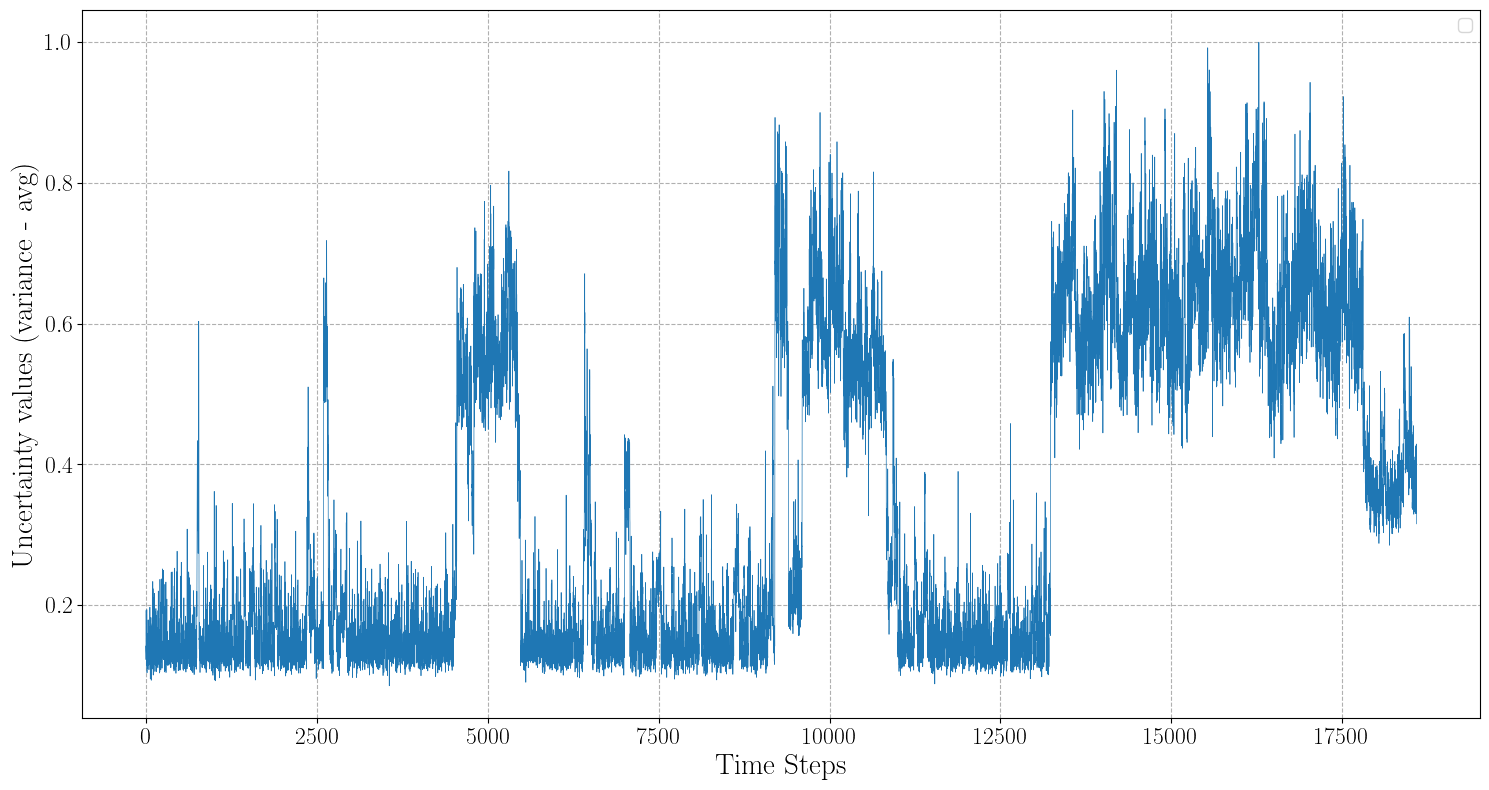

In [8]:
# Plotting the average eigenfunction with uncertainty

i = 1  # Index of the eigenfunction to plot
fig, ax = plt.subplots(figsize=(15, 8))

avg = np.real(avg_eigfuncs[i, :])
plus = np.real(eigfuncs_plus[i, :])
minus = np.real(eigfuncs_minus[i, :])
norm = np.amax(np.abs(avg))
avg /= norm

local_uncertainty = np.abs(plus - minus) / 2
local_uncertainty /= np.max(local_uncertainty)

xx = np.arange(data_X.shape[1])  # or use time = data_X[0, :] if those are actual time points

### Plot the average eigenfunction

ax.plot(xx, local_uncertainty, linewidth=0.5)
# ax.plot(xx, avg, color='black', linewidth=0.5, label=fr"$\varphi_{i+1}$")
# ax.plot(xx, avg + local_uncertainty, color='red', linewidth=0.5, label='Upper Bound')
# ax.plot(xx, avg - local_uncertainty, color='blue', linewidth=0.5, label='Lower Bound')

# ax.fill_between(xx, avg - local_uncertainty, avg + local_uncertainty,
#                 color='green', alpha=0.3, label='Uncertainty')

# Labels and appearance
ax.set_xlabel('Time Steps', fontsize=21)
ax.set_ylabel('Uncertainty values (variance - avg)', fontsize=21)
ax.grid(which='major', linestyle='--')
ax.grid(which='minor', linestyle=':')
#ax.set_title("Eigenfunction with Local Uncertainty", fontsize=18)
ax.legend(fontsize=12)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.tight_layout()
#plt.savefig('nug2_eigfunc_uncertainty.png')
plt.show()
